# Lab 2: Discovery of Frequent Itemsets and Association

In [5]:
with open("../datasets/transactions.dat", "rb") as f:
    chunk = f.read(300)

print(chunk)

b'25 52 164 240 274 328 368 448 538 561 630 687 730 775 825 834 \n39 120 124 205 401 581 704 814 825 834 \n35 249 674 712 733 759 854 950 \n39 422 449 704 825 857 895 937 954 964 \n15 229 262 283 294 352 381 708 738 766 853 883 966 978 \n26 104 143 320 569 620 798 \n7 185 214 350 529 658 682 782 809 849 883'


## Setup

First install all of the required dependencies.

In [2]:
!sudo apt-get update -qq
!sudo apt-get install -y -qq --no-install-recommends openjdk-17-jre-headless
%pip install -q pyspark sympy matplotlib

debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 10.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (Can't locate Term/ReadLine.pm in @INC (you may need to install the Term::ReadLine module) (@INC entries checked: /etc/perl /usr/local/lib/x86_64-linux-gnu/perl/5.40.1 /usr/local/share/perl/5.40.1 /usr/lib/x86_64-linux-gnu/perl5/5.40 /usr/share/perl5 /usr/lib/x86_64-linux-gnu/perl-base /usr/lib/x86_64-linux-gnu/perl/5.40 /usr/share/perl/5.40 /usr/local/lib/site_perl) at /usr/share/perl5/Debconf/FrontEnd/Readline.pm line 8, <STDIN> line 10.)
debconf: falling back to frontend: Teletype
Selecting previously unselected package libsqlite3-0:amd64.
(Reading database ... 9462 files and directories currently installed.)
Preparing to unpack .../0-libsqlite3-0_3.46.1-9ubuntu0.3_a

Next up, create the instance of Spark and configure it with basic parameters.

In [3]:
import os, sys, subprocess
os.environ["PYSPARK_PYTHON"] = sys.executable

print(subprocess.run(["java", "-version"], capture_output=True, text=True).stderr)

from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .appName("lab1")
         .master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.network.timeout", "600s")
         .config("spark.executor.heartbeatInterval", "60s")
         .getOrCreate())

sc = spark.sparkContext

print(spark.version)

openjdk version "17.0.21.0.3" 2026-10-24
OpenJDK Runtime Environment (build 17.0.21.0.3+1-1-26.04.1-Ubuntu)
OpenJDK 64-Bit Server VM (build 17.0.21.0.3+1-1-26.04.1-Ubuntu, mixed mode, sharing)



Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/17 11:20:29 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


4.3.0


## Finding frequent itemsets

In [4]:
baskets = (sc.textFile("../datasets/transactions.dat")
            .map(lambda line: tuple(sorted(set(map(int, line.split())))))
            .filter(len)
            .cache())

print(baskets.count())

[Stage 0:>                                                          (0 + 2) / 2]

100000


In [5]:
from itertools import combinations
from operator import add

class Apriori:
    def __init__(self, support: float):
        self.s = support

    def find_frequent_itemsets(self, baskets_rdd) -> dict[int, dict[tuple, int]]:
        sc = baskets_rdd.context
        min_count = self.s * baskets_rdd.count()
        result = {}

        singles = (baskets_rdd.flatMap(lambda b: b)
                              .map(lambda x: ((x,), 1))
                              .reduceByKey(add)
                              .filter(lambda kv: kv[1] >= min_count)
                              .collectAsMap())
        result[1] = singles

        frequent_items = sorted(t[0] for t in singles)

        k = 2

        while result[k - 1]:
            candidates = self._generate_candidates(set(result[k - 1]), frequent_items, k)

            if not candidates:
                break

            bc = sc.broadcast(candidates)

            counts = (baskets_rdd
                      .flatMap(lambda b: [(c, 1) for c in combinations(b, k) if c in bc.value])
                      .reduceByKey(add)
                      .filter(lambda kv: kv[1] >= min_count)
                      .collectAsMap())

            bc.unpersist()

            if not counts:
                break

            result[k] = counts
            k += 1

        return result

    def _generate_candidates(self, prev_frequent: set[tuple], frequent_items: list[int], k: int) -> set[tuple]:
        candidates = set()

        for itemset in prev_frequent:
            last = itemset[-1]

            for x in frequent_items:
                if x <= last:
                    continue

                candidate = itemset + (x,)

                if all(sub in prev_frequent for sub in combinations(candidate, k - 1)):
                    candidates.add(candidate)

        return candidates

In [8]:
apriori = Apriori(support=0.01)

levels = apriori.find_frequent_itemsets(baskets)
print(levels[3])

[Stage 6:>                                                          (0 + 2) / 2]

{(39, 704, 825): 1035}


## Generating association rules

In [6]:
class AprioriRules(Apriori):
    def __init__(self, support: float, confidence: float):
        super().__init__(support)
        self.c = confidence

    def generate_association_rules(self, levels: dict[int, dict[tuple, int]]) -> list[tuple[tuple, tuple, float]]:
        counts = {}
        
        for level in levels.values():
            counts.update(level)

        rules = []
        
        for k, itemsets in levels.items():
            if k < 2:
                continue
                
            for itemset, count in itemsets.items():
                rules.extend(self._rules_for_itemset(itemset, count, counts))
        
        return rules

    def _rules_for_itemset(self, itemset: tuple, itemset_count: int, counts: dict) -> list:
        rules = []
        consequents = [(item,) for item in itemset]
        
        m = 1

        while consequents and m < len(itemset):
            surviving = []

            for cons in consequents:
                antecedent = tuple(x for x in itemset if x not in cons)
                confidence = itemset_count / counts[antecedent]

                if confidence >= self.c:
                    surviving.append(cons)
                    rules.append((antecedent, cons, confidence))

            m += 1
            consequents = self._generate_candidates(set(surviving), sorted(itemset), m)

        return rules

In [9]:
apriori_rules = AprioriRules(support=0.01, confidence=0.6)

levels = apriori.find_frequent_itemsets(baskets)
print(levels[2])

rules = apriori_rules.generate_association_rules(levels)
print(rules)

[Stage 13:>                                                         (0 + 2) / 2]

{(39, 825): 1187, (789, 829): 1194, (368, 682): 1193, (390, 722): 1042, (39, 704): 1107, (704, 825): 1102, (227, 390): 1049, (368, 829): 1194, (217, 346): 1336}
[((704,), (39,), 0.617056856187291), ((704,), (825,), 0.6142697881828316), ((704, 825), (39,), 0.9392014519056261), ((39, 825), (704,), 0.8719460825610783), ((39, 704), (825,), 0.9349593495934959)]


## Evaluation

In [10]:
import time
import numpy as np
import matplotlib.pyplot as plt

all_baskets = baskets.collect()
N_ALL = len(all_baskets)

def timed(fn):
    t0 = time.perf_counter()
    out = fn()
    return out, time.perf_counter() - t0

def make_rdd(n):
    rdd = sc.parallelize(all_baskets[:n], numSlices=16).cache()
    rdd.count()
    return rdd

SUPPORT, RUNS = 0.01, 3
sizes = [1_000, 10_000, 100_000]

r = make_rdd(1_000)
Apriori(SUPPORT).find_frequent_itemsets(r)
r.unpersist()

scal = {}

for n in sizes:
    rdd = make_rdd(n)
    ts = [timed(lambda: Apriori(SUPPORT).find_frequent_itemsets(rdd))[1] for _ in range(RUNS)]
    scal[n] = sorted(ts)[RUNS // 2] 
    rdd.unpersist()
    print(n, round(scal[n], 2), "s")

supports = [0.02, 0.01, 0.005, 0.0025]
rdd = make_rdd(N_ALL)
sweep, levels_by_s = {}, {}

for s in supports:
    levels, t = timed(lambda: Apriori(s).find_frequent_itemsets(rdd))
    levels_by_s[s] = levels
    sweep[s] = {"time": t,
                "per_level": {k: len(v) for k, v in levels.items()},
                "total": sum(len(v) for v in levels.values())}
    print(s, round(t, 1), "s", sweep[s]["per_level"])

1000 2.15 s
10000 1.45 s


100000 2.96 s


0.02 1.3 s {1: 155}


0.01 2.9 s {1: 375, 2: 9, 3: 1}


0.005 14.6 s {1: 569, 2: 342, 3: 110, 4: 43, 5: 9}


[Stage 147:===================================================>   (15 + 1) / 16]

0.0025 43.1 s {1: 717, 2: 2661, 3: 2014, 4: 1315, 5: 667, 6: 253, 7: 66, 8: 10}


In [17]:
S_RULES, C_RULES = 0.005, 0.5
levels = levels_by_s[S_RULES]

rules = AprioriRules(S_RULES, C_RULES).generate_association_rules(levels)

counts = {}

for lv in levels.values():
    counts.update(lv)

rows = []

for lhs, rhs, conf in rules:
    rows.append(dict(
        lhs=lhs, rhs=rhs,
        support=counts[tuple(sorted(lhs + rhs))] / N_ALL,
        confidence=conf,
        interest=conf - counts[rhs] / N_ALL,
    ))

print(len(rows), "rules")

for r in sorted(rows, key=lambda r: -r["interest"])[:10]:
    print(r["lhs"], "->", r["rhs"],
          f"supp={r['support']:.4f}  conf={r['confidence']:.2f}  interest={r['interest']:.2f}")

1145 rules
(185, 471, 960) -> (678,) supp=0.0065  conf=0.99  interest=0.97
(217, 661, 923, 947) -> (546,) supp=0.0056  conf=0.98  interest=0.97
(217, 661, 947) -> (546,) supp=0.0057  conf=0.98  interest=0.97
(471, 678, 960) -> (185,) supp=0.0065  conf=0.98  interest=0.97
(661, 923, 947) -> (546,) supp=0.0058  conf=0.98  interest=0.97
(217, 661, 923) -> (546,) supp=0.0057  conf=0.98  interest=0.97
(185, 678) -> (471, 960) supp=0.0065  conf=0.98  interest=0.97
(185, 678, 960) -> (471,) supp=0.0065  conf=0.99  interest=0.96
(217, 546, 947) -> (661,) supp=0.0057  conf=0.99  interest=0.96
(217, 546, 923) -> (661,) supp=0.0057  conf=0.99  interest=0.96


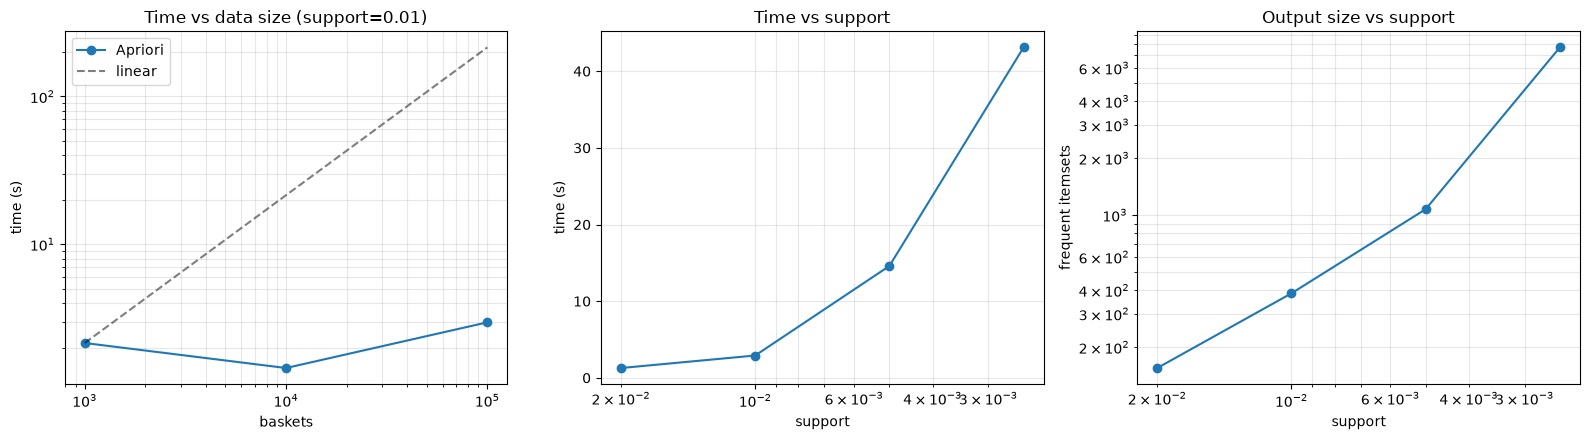

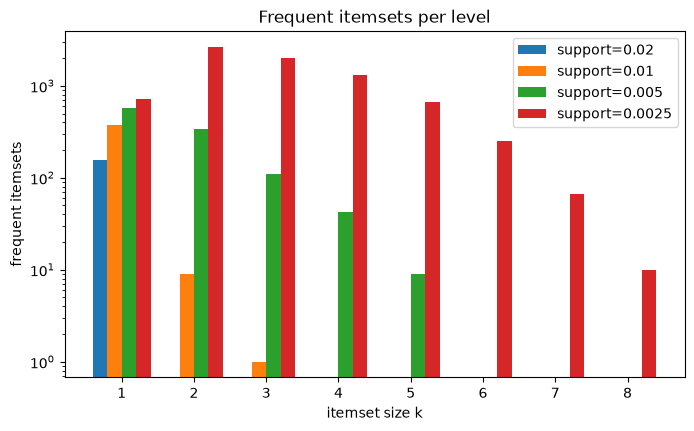

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# 1: time vs data size (log-log, with a linear-scaling reference)
ax[0].loglog(sizes, [scal[n] for n in sizes], "o-", label="Apriori")
ax[0].loglog(sizes, [scal[sizes[0]] * n / sizes[0] for n in sizes], "k--", alpha=.5, label="linear")
ax[0].set(xlabel="baskets", ylabel="time (s)", title=f"Time vs data size (support={SUPPORT})")
ax[0].legend()

# 2: time vs support
ax[1].semilogx(supports, [sweep[s]["time"] for s in supports], "o-")
ax[1].set(xlabel="support", ylabel="time (s)", title="Time vs support")
ax[1].invert_xaxis()

# 3: output size vs support
ax[2].loglog(supports, [sweep[s]["total"] for s in supports], "o-")
ax[2].set(xlabel="support", ylabel="frequent itemsets", title="Output size vs support")
ax[2].invert_xaxis()

for a in ax:
    a.grid(alpha=.3, which="both")
    
plt.tight_layout(); plt.show()

# 4: frequent itemsets per level, one bar group per support
max_k = max(max(sweep[s]["per_level"]) for s in supports)
x, w = np.arange(1, max_k + 1), 0.8 / len(supports)

plt.figure(figsize=(8, 4.5))

for i, s in enumerate(supports):
    plt.bar(x + i * w, [sweep[s]["per_level"].get(k, 0) for k in x], w, label=f"support={s}")
    
plt.yscale("log")
plt.xlabel("itemset size k"); plt.ylabel("frequent itemsets")
plt.xticks(x + 0.4 - w / 2, x)
plt.title("Frequent itemsets per level"); plt.legend(); plt.show()

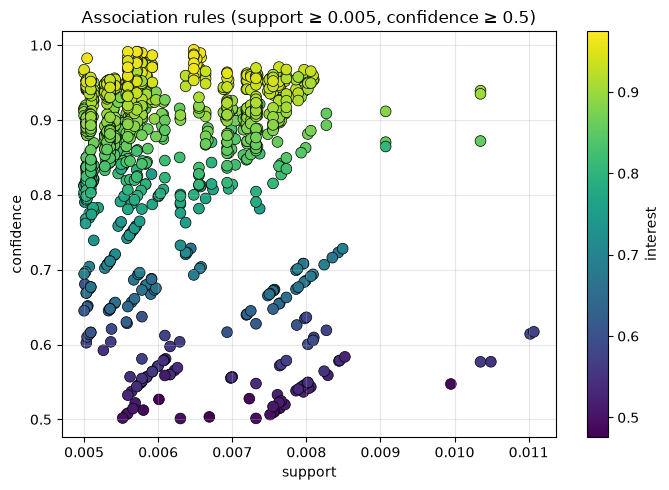

In [18]:
## 5: scatter plot of the association rules' confidence and interest
plt.figure(figsize=(7, 5))

sca = plt.scatter([r["support"] for r in rows],
                  [r["confidence"] for r in rows],
                  c=[r["interest"] for r in rows],
                  cmap="viridis", s=60, edgecolors="k", linewidths=0.5)

plt.colorbar(sca, label="interest")
plt.xlabel("support"); plt.ylabel("confidence")
plt.title(f"Association rules (support ≥ {S_RULES}, confidence ≥ {C_RULES})")
plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Conclusions